# Online advanced augmentation only, on the base dataset (ST-GCN, one run)

Fills the missing cell in the premise comparison (`paper_premise_test.ipynb`): the advanced bundle applied online to the
dataset **as it is**, with no synthetic clips and no class balancing.

| arm | training set | online augmentation | class balancing |
|---|---|---|---|
| `raw` | base dataset | none | none |
| `offline_basic` | built up to 500 | none | none |
| `offline_basic_online_advanced` | built up to 500 | advanced | none |
| **`online_advanced`** (this notebook) | base dataset | advanced, fresh every epoch | none |

Everything else is identical to the premise notebook: the tuned recipe in `configs/stgcn_recipe.json`, `body_court` input, 9 blocks,
seed 42, checkpoint chosen on validation MCA, test set evaluated once and never used to choose. If the earlier three arms have been run,
their saved predictions are loaded for the comparison, otherwise the tables show this arm alone.

One seed is a first look: seed spread is about 1 point of top-1 and 1 to 3 points of MCA, and seven classes have 11 to 13 test clips.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task
from sklearn.metrics import precision_recall_fscore_support

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
sys.path.insert(0, REPO)
import dataset as ds
from models import stgcn as stgcn_model
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/paper_premise_test"
KEYPOINTS = f"{DATA}/keypoints_interp"
OUT = f"{OUTPUTS}/experiments/paper_premise_test"          # same folder as the premise notebook, so the arms sit together
os.makedirs(OUT, exist_ok=True)

SEED, ARM = 42, "online_advanced"
SPLITS = ("train", "val", "test")
NORMALISATION, USE_COURT = "body", True
NUM_WORKERS, EVAL_WORKERS = 20, 8
SELECT_METRIC = "mca"
RARE_THRESHOLD = 150
OTHER_ARMS = ["raw", "offline_basic", "offline_basic_online_advanced"]

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)

manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
short = [c.split("_", 1)[1] for c in class_names]
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]
train_counts = manifest[manifest["split"] == "train"]["class_name"].value_counts().reindex(class_names)
test_counts = manifest[manifest["split"] == "test"]["class_name"].value_counts().reindex(class_names)
rare_ids = [i for i, n in enumerate(train_counts.to_numpy()) if n < RARE_THRESHOLD]
common_ids = [i for i in range(K) if i not in rare_ids]
in_channels = stgcn_model.n_channels(USE_COURT)
forward = stgcn_model.make_forward(USE_COURT)
print("recipe:", RECIPE)
print(f"{int(train_counts.sum())} training clips, {len(rare_ids)} limited sample classes (under {RARE_THRESHOLD})")

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
recipe: {'model': 'ST-GCN', 'normalisation': 'body_court', 'selected': 'combination', 'changes_from_baseline': {'weight_decay': 0.005, 'target_per_class': 300}, 'augmentation': 'advanced', 'min_native_frames': 5, 'batch_size': 16, 'lr': 0.01, 'momentum': 0.9, 'gamma': 0.1, 'select_metric': 'top1', 'weight_decay': 0.005, 'label_smoothing': 0.0, 'schedule': 'step10', 'target_per_class': 300, 'num_epochs': 60, 'patience': 20, 'tuning': {'seeds': [11, 22], 'val_top1': 0.7612, 'baseline_val_top1': 0.7394}}
6247 training clips, 8 limited sample classes (under 150)


## Smoke test

The training set is the base dataset (no synthetic clips), natural frequencies (no sampler), online augmentation really changes a clip
between draws, and one training step runs. Run this cell alone first.

In [3]:
tr.seed_everything(0)
loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, "advanced", NORMALISATION, seed=0,
                           batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                           num_workers=2, eval_workers=2, balanced=False)
assert len(loaders["train"].dataset) == int(train_counts.sum()), "training set is not the base dataset"
one = manifest[manifest["split"] == "train"].iloc[:1].reset_index(drop=True)
d = ds.BadmintonPoseDataset(one, KEYPOINTS, class_to_id, "advanced", NORMALISATION)
draws = [np.asarray(d[0]["keypoints"]) for _ in range(6)]
assert any(not np.array_equal(draws[0], x) for x in draws[1:]), "online augmentation did nothing"

model = stgcn_model.build_stgcn(in_channels, K).to(device)
batch = next(iter(loaders["train"]))
logits = forward(model, batch, device)
assert logits.shape == (RECIPE["batch_size"], K)
nn.CrossEntropyLoss()(logits, batch["label"].to(device)).backward()
print(f"{len(loaders['train'].dataset)} training clips, {len(loaders['train'])} steps per epoch; smoke test passed")
del model, loaders

6247 training clips, 391 steps per epoch; smoke test passed


In [4]:
run_name = f"stgcn_premise_{ARM}_s{SEED}"
results_path = f"{OUT}/results_{ARM}.csv"
if os.path.exists(results_path):
    print("already done, loading", results_path)
else:
    print(f"=== {run_name} ===")
    tr.seed_everything(SEED)
    task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                     tags=["paper_premise_test", ARM, "stgcn", f"seed{SEED}"], reuse_last_task_id=False,
                     auto_connect_frameworks={"matplotlib": False, "pytorch": False})
    task.connect({**RECIPE, "arm": ARM, "policy": "advanced", "offline": False, "seed": SEED,
                  "select_metric": SELECT_METRIC, "balanced": False, "keypoints": KEYPOINTS, "split_sha256": split_hash})
    loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, "advanced", NORMALISATION, seed=SEED,
                               batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                               num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS, balanced=False)
    model = stgcn_model.build_stgcn(in_channels, K).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=RECIPE["lr"], momentum=RECIPE["momentum"],
                                weight_decay=RECIPE["weight_decay"])
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=RECIPE["gamma"])
    criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])
    _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                            task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                            patience=RECIPE.get("patience", 20), select_metric=SELECT_METRIC,
                                            splits=SPLITS)
    metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                            out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                            extra={"arm": ARM, "seed": SEED})
    task.close()
    pd.DataFrame([metrics]).to_csv(results_path, index=False)
    del model, loaders
    torch.cuda.empty_cache()

=== stgcn_premise_online_advanced_s42 ===
ClearML Task: created new task id=1fbec2f33e0a44fdae086c1d7b6a97e4
2026-10-08 06:11:51,389 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/fe4553691bdd448cad7d093b368fb533/tasks/1fbec2f33e0a44fdae086c1d7b6a97e4/output/log
epoch   0  loss 1.833  train 0.550  val 0.543 (mca 0.358)  *
epoch   1  loss 1.425  train 0.594  val 0.607 (mca 0.420)  *
epoch   2  loss 1.299  train 0.671  val 0.665 (mca 0.467)  *
epoch   3  loss 1.236  train 0.642  val 0.634 (mca 0.487)  *
epoch   4  loss 1.198  train 0.686  val 0.671 (mca 0.489)  *
epoch   5  loss 1.163  train 0.640  val 0.626 (mca 0.478)
epoch   6  loss 1.143  train 0.689  val 0.671 (mca 0.508)  *
epoch   7  loss 1.133  train 0.707  val 0.697 (mca 0.518)  *
epoch  10  loss 0.939  train 0.758  val 0.712 (mca 0.556)  *
epoch  11  loss 0.880  train 0.768  val 0.729 (mca 0.577)  *
epoch  12  loss 0.849  train 0.781  val

███████████████████████████████ 100% | 11.66/11.66 MB [00:03<00:00,  3.37MB/s]: 


## Results

Computed from the saved per clip predictions, identically for every arm. The earlier arms are included only if their run folders exist.

In [5]:
def read_split(arm, split):
    p = pd.read_csv(f"{OUT}/stgcn_premise_{arm}_s{SEED}/stgcn_premise_{arm}_s{SEED}_predictions.csv")
    p = p[p["split"] == split].sort_values("filepath").reset_index(drop=True)
    top5 = np.array([lab in t.split(";") for lab, t in zip(p["label"], p["top5"].fillna(""))])
    return p["filepath"].to_numpy(), p["label"].map(class_to_id).to_numpy(), p["pred"].map(class_to_id).to_numpy(), top5


def metrics_from(pred, y, top5=None):
    p, r, f1, n = precision_recall_fscore_support(y, pred, labels=list(range(K)), zero_division=0)
    out = {"top1": (pred == y).mean(), "mca": r.mean(), "macro_f1": f1.mean(),
           "limited sample recall": r[rare_ids].mean(), "common recall": r[common_ids].mean()}
    if top5 is not None:
        out["top5"] = top5.mean()
    return out, p, r, f1


arms = [a for a in OTHER_ARMS + [ARM]
        if os.path.exists(f"{OUT}/stgcn_premise_{a}_s{SEED}/stgcn_premise_{a}_s{SEED}_predictions.csv")]
print("arms found:", arms)
test = {a: read_split(a, "test") for a in arms}
val = {a: read_split(a, "val") for a in arms}
labels = test[ARM][1]
assert all((test[a][0] == test[ARM][0]).all() for a in arms)

rows, f1s = [], {}
for a in arms:
    m, p, r, f1 = metrics_from(test[a][2], labels, test[a][3])
    f1s[a] = f1
    mv = metrics_from(val[a][2], val[a][1])[0]
    rows.append({"arm": a, "test top1": m["top1"], "test top5": m["top5"], "test mca": m["mca"], "test macro f1": m["macro_f1"],
                 "limited sample recall": m["limited sample recall"], "common recall": m["common recall"],
                 "val mca (selection)": mv["mca"], "val top1": mv["top1"]})
summary = pd.DataFrame(rows).set_index("arm")
show = (100 * summary).round(2)
own = pd.read_csv(results_path)
show.loc[ARM, "train top1"] = round(100 * own["train_top1"].iloc[0], 2)
show.loc[ARM, "best epoch"] = int(own["best_epoch"].iloc[0])
show

arms found: ['raw', 'offline_basic', 'offline_basic_online_advanced', 'online_advanced']


,test top1,test top5,test mca,test macro f1,limited sample recall,common recall,val mca (selection),val top1,train top1,best epoch
arm,,,,,,,,,,
raw,70.59,93.73,56.41,57.77,40.63,69.04,63.92,74.90,NaN,NaN
offline_basic,67.90,94.25,57.84,57.58,50.75,63.50,65.25,71.57,NaN,NaN
offline_basic_online_advanced,72.38,94.76,61.79,63.40,54.23,67.83,67.24,76.70,NaN,NaN
online_advanced,73.27,94.88,56.95,58.77,37.84,72.23,62.78,75.54,87.69,24.0


In [6]:
f1_table = pd.DataFrame({"train clips": train_counts.to_numpy(), "test clips": test_counts.to_numpy()}, index=short)
for a in arms:
    f1_table[f"F1 {a}"] = 100 * f1s[a]
if "raw" in arms:
    f1_table[f"{ARM} - raw"] = f1_table[f"F1 {ARM}"] - f1_table["F1 raw"]
f1_table["limited sample"] = [k in rare_ids for k in range(K)]
f1_table = f1_table.sort_values("train clips", ascending=False)
f1_table.round(1)

,train clips,test clips,F1 raw,F1 offline_basic,F1 offline_basic_online_advanced,F1 online_advanced,online_advanced - raw,limited sample
Long Serve,791,99,95.0,94.6,96.4,96.5,1.4,False
Clear,755,95,77.2,72.7,75.7,78.9,1.7,False
Short Serve,703,88,95.0,96.1,97.8,97.1,2.2,False
Smash,657,82,81.2,71.1,83.2,84.1,2.9,False
Drop Shot,650,81,72.7,72.7,73.6,80.5,7.7,False
Lift,604,76,61.1,60.8,57.9,58.9,-2.2,False
Cut,468,59,65.6,60.6,66.7,67.2,1.6,False
Push Shot,320,40,35.2,36.8,34.1,43.3,8.1,False
Flat Shot,262,32,24.6,19.2,13.3,9.8,-14.8,False
Block,252,31,55.4,56.1,61.8,61.9,6.5,False


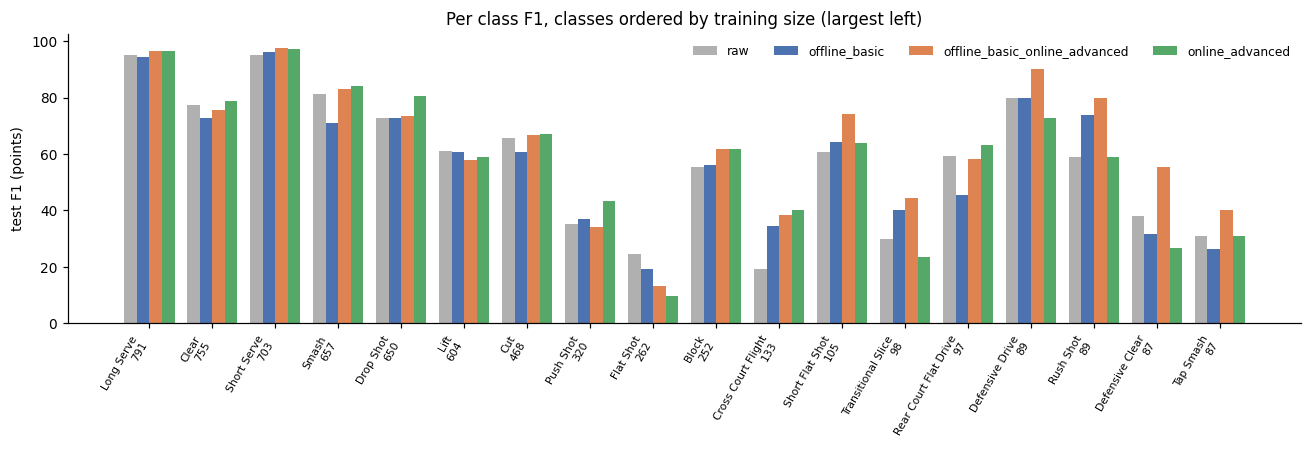

In [7]:
order = list(f1_table.index)
x = np.arange(K)
fig, ax = plt.subplots(figsize=(12, 4.2))
w = 0.8 / len(arms)
palette = {"raw": "#b0b0b0", "offline_basic": "#4c72b0", "offline_basic_online_advanced": "#dd8452", ARM: "#55a868"}
for i, a in enumerate(arms):
    ax.bar(x + (i - (len(arms) - 1) / 2) * w, f1_table.loc[order, f"F1 {a}"], w, label=a, color=palette[a])
ax.set_xticks(x, [f"{n}\n{int(f1_table.loc[n, 'train clips'])}" for n in order], rotation=60, ha="right", fontsize=7)
ax.set_ylabel("test F1 (points)")
ax.set_title("Per class F1, classes ordered by training size (largest left)")
ax.legend(frameon=False, ncol=len(arms), fontsize=8)
fig.tight_layout()
plt.show()

In [8]:
task = Task.init(project_name=PROJECT, task_name=f"premise_{ARM}_summary", task_type=Task.TaskTypes.qc,
                 tags=["paper_premise_test", "summary", ARM], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
log = task.get_logger()
task.connect({**RECIPE, "seed": SEED, "select_metric": SELECT_METRIC, "arms": arms, "split_sha256": split_hash})
log.report_table("test summary", "test", iteration=0, table_plot=show.reset_index())
log.report_table("per class F1", "test", iteration=0, table_plot=f1_table.round(1).reset_index().rename(columns={"index": "class"}))
log.report_matplotlib_figure("per class F1", "test", figure=fig, iteration=0, report_interactive=False)
show.to_csv(f"{OUT}/summary_{ARM}.csv")
f1_table.to_csv(f"{OUT}/per_class_f1_{ARM}.csv")
task.close()

Failed accessing the jupyter server(s): []


ClearML Task: created new task id=6265e6bd3a7e41b2addf209863342872
ClearML results page: https://app.clear.ml/projects/fe4553691bdd448cad7d093b368fb533/tasks/6265e6bd3a7e41b2addf209863342872/output/log


## How to read this

- **Against `raw`:** the cleanest read of what online augmentation alone does, since the training set and balancing are identical.
- **Against `offline_basic_online_advanced`:** isolates what the synthetic build-up adds once the advanced bundle is already applied.
- Earlier multi seed work (notebook 14) found online augmentation on the base dataset mainly moves MCA and limited sample recall, not top-1;
  that note used the class balanced sampler, which this arm does not. One seed cannot separate gaps under about 3 MCA points from noise.